In [1]:
import pandas as pd
import numpy as np
import umap
import hdbscan
from sentence_transformers import SentenceTransformer

In [2]:
# Load data
df = pd.read_csv("election_cleaned.csv")

In [5]:
# Ensure no NaN values and all text is string
df["cleaned_tweet"] = df["cleaned_tweet"].astype(str).fillna("")


In [6]:
df["cleaned_tweet"].isna().sum()


np.int64(0)

In [7]:
# Load pre-trained Sentence-BERT model
model = SentenceTransformer('all-MiniLM-L6-v2')  # Fast & good for clustering

In [8]:
# Convert tweets into embeddings
embeddings = model.encode(df["cleaned_tweet"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

In [10]:
# Reduce dimensionality using UMAP
umap_model = umap.UMAP(n_neighbors=15, n_components=5, metric='cosine', random_state=42)
umap_embeddings = umap_model.fit_transform(embeddings)

C:\Users\Rheah\anaconda3\envs\sentiment_env\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Rheah\anaconda3\envs\sentiment_env\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [11]:
# Apply HDBSCAN clustering
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, metric='euclidean', cluster_selection_method='eom')
df["cluster"] = clusterer.fit_predict(umap_embeddings)

C:\Users\Rheah\anaconda3\envs\sentiment_env\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Rheah\anaconda3\envs\sentiment_env\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [12]:
# Show cluster counts
print(df["cluster"].value_counts())

cluster
-1      21257
 3       1781
 307     1441
 271     1318
 166     1101
        ...  
 120       15
 253       15
 234       15
 211       15
 236       15
Name: count, Length: 321, dtype: int64


In [13]:
# Sample tweets from each cluster
for cluster_num in df["cluster"].unique():
    print(f"\nCluster {cluster_num} Examples:")
    print(df[df["cluster"] == cluster_num]["cleaned_tweet"].head(5).tolist())


Cluster 113 Examples:
['continued to develop a technique for hiding evidence of human tampering in laboratorycreated super viruses by robert f kennedy jr j jay couey phd charles rixey', 'rfk jr didnt say that covid was ethnically targeted he gave it as an example of a virus discriminates between ethnic groups and that such discriminations could be exploited with bioweapons if you dont understand the difference you dont know enough to report on this', 'never forget what and did to americans during covid there will be several consequences to these individuals over the next four years and the american people will never forget or forgive them they set the back a generation', 'rfk jr told a bunch of people the government may have planned covid yes lets definitely put a conspiracy theorist in charge of a major government health agency covidimpact360 mylongcovidadvocacy', 'sad days ahead rfk jr said his organization funded viral covid conspiracy film plandemic rolling stone']

Cluster 299 Ex

In [14]:
noise_ratio = (df['cluster'] == -1).sum() / len(df) * 100
print(f"Noise percentage: {noise_ratio:.2f}%")


Noise percentage: 42.51%


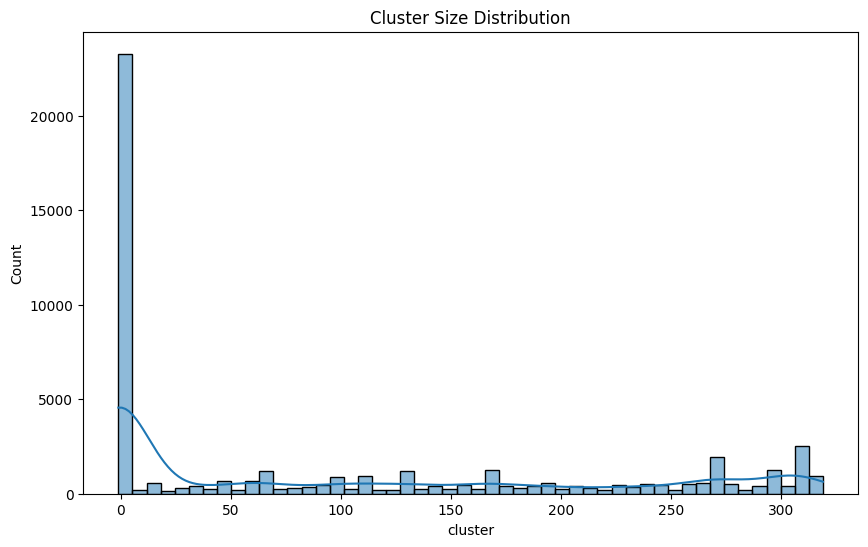

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(df['cluster'], bins=50, kde=True)
plt.title("Cluster Size Distribution")
plt.show()


In [16]:
for cluster_id in df['cluster'].value_counts().index[:5]:  # Top 5 clusters
    print(f"\nCluster {cluster_id}:")
    print(df[df['cluster'] == cluster_id]['cleaned_tweet'].sample(5, random_state=42).tolist())



Cluster -1:
['with rfk jr', 'bullshit', 'so kamala harris cant even get the majority vote in her own party', 'i would be its bcause of his gf rosario dawson who supports rfk jr spots on agriculture and soil in the environment', 'tonight its a warm fire and a good movie whats your plans']

Cluster 3:
['nan', 'nan', 'nan', 'nan', 'nan']

Cluster 307:
['my advice to them would be to work out eat right get off the internet and go to church before long youll leave the democratic party too', 'the corbynization of the democratic party continues apace senate democrats launch eleventhhour cam', 'what do you call the democratic party', 'i mean thats thats the democratic party theres what they should do and then theres what they will do due to their ideas of decorum lets not gang up on the first out trans congresswoman for being a lib', 'we all knew that and we didnt have to be an expert but the democratic party are going to stick their head in the sand wave their white flag all for a peaceful t

In [17]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,  # Increase for more stable clusters
    min_samples=5,        # Reduce to make HDBSCAN less strict
    metric='cosine',      # Better for text embeddings
    cluster_selection_method='eom'
)


In [18]:
df['cluster'].value_counts()


cluster
-1      21257
 3       1781
 307     1441
 271     1318
 166     1101
        ...  
 120       15
 253       15
 234       15
 211       15
 236       15
Name: count, Length: 321, dtype: int64

In [ ]:
from transformers import pipeline

# Load Sentiment Analysis Pipeline
sentiment_pipeline = pipeline("sentiment-analysis")

# Apply to tweets
df["sentiment"] = df["cleaned_tweet"].apply(lambda x: sentiment_pipeline(x)[0]['label'])


In [ ]:
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
